Feature 6개로 무드 점수를 계산해서 7개 무드(Chill, Focus, Romantic, Happy, Sad, Energetic, Dreamy) 중 하나로 라벨링

- 각 Feature를 전체 곡 기준 순위(0~1)로 바꾼 뒤 가중합으로 점수 계산
- 점수가 가장 높은 무드를 곡의 무드로 지정

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

sns.set_theme(style="whitegrid")

In [2]:
df = pd.read_csv("../data/processed/tracks_clean.csv")

print(df.shape)
df.head()

(76630, 21)


,unnamed:_0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,...,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,...,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,...,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,...,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,...,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


In [4]:
features = ["danceability", "energy", "tempo", "acousticness", "instrumentalness", "valence"]

df[features].describe().T

,count,mean,std,min,25%,50%,75%,max
danceability,76630.0,0.562291,0.173095,0.05130,0.4520,0.574000,0.68900,0.985
energy,76630.0,0.636913,0.257246,0.00002,0.4570,0.679000,0.85800,1.000
tempo,76630.0,122.422034,29.933196,30.20000,99.0550,122.002000,141.01975,243.372
acousticness,76630.0,0.332487,0.338908,0.00000,0.0177,0.198000,0.63200,0.996
instrumentalness,76630.0,0.167611,0.319149,0.00000,0.0000,0.000057,0.07740,1.000
valence,76630.0,0.471373,0.260929,0.00000,0.2540,0.459000,0.68200,0.995


In [5]:
ranked = df[features].rank(pct=True)

ranked.head()

,danceability,energy,tempo,acousticness,instrumentalness,valence
0,0.723372,0.253726,0.129231,0.295433,0.332787,0.786037
1,0.201853,0.058274,0.050992,0.926511,0.403954,0.264550
2,0.228442,0.166834,0.044043,0.508782,0.166162,0.097155
3,0.061588,0.020938,0.976243,0.914426,0.508691,0.119092
4,0.597860,0.236683,0.462449,0.664851,0.166162,0.146509


In [6]:
danceability = ranked["danceability"]
energy = ranked["energy"]
tempo = ranked["tempo"]
acousticness = ranked["acousticness"]
instrumentalness = ranked["instrumentalness"]
valence = ranked["valence"]

#### 무드별 점수 계산

In [7]:
mood_scores = pd.DataFrame(index=df.index)

mood_scores["chill"] = (
    (1 - energy) * 0.35 + (1 - tempo) * 0.25 + acousticness * 0.25 + (1 - danceability) * 0.15
)

mood_scores["focus"] = (
    instrumentalness * 0.40 + acousticness * 0.25 + (1 - danceability) * 0.20 + (1 - energy) * 0.15
)

mood_scores["romantic"] = (
    acousticness * 0.30
    + (1 - energy) * 0.25
    + (1 - tempo) * 0.20
    + valence * 0.15
    + (1 - danceability) * 0.10
)

mood_scores["happy"] = valence * 0.45 + energy * 0.25 + danceability * 0.20 + tempo * 0.10

mood_scores["sad"] = (
    (1 - valence) * 0.45 + (1 - energy) * 0.30 + acousticness * 0.15 + (1 - tempo) * 0.10
)

mood_scores["energetic"] = energy * 0.40 + danceability * 0.25 + tempo * 0.20 + valence * 0.15

mood_scores["dreamy"] = (
    acousticness * 0.35 + instrumentalness * 0.25 + (1 - danceability) * 0.20 + (1 - energy) * 0.20
)

mood_scores.head()

,chill,focus,romantic,happy,sad,energetic,dreamy
0,0.594241,0.374240,0.594920,0.574746,0.451557,0.426085,0.391179
1,0.918206,0.694098,0.822684,0.179086,0.847348,0.123654,0.773242
2,0.773527,0.472947,0.643847,0.135521,0.828143,0.147226,0.540559
3,0.717979,0.766625,0.635550,0.168768,0.829667,0.236885,0.830717
4,0.628082,0.427603,0.559985,0.290917,0.766549,0.358604,0.507330


#### 가장 높은 점수의 무드 지정

In [8]:
df["mood"] = mood_scores.idxmax(axis=1)
df["mood_score"] = mood_scores.max(axis=1)

df[["track_name", "artists", "mood", "mood_score"]].head(10)

,track_name,artists,mood,mood_score
0,Comedy,Gen Hoshino,romantic,0.594920
1,Ghost - Acoustic,Ben Woodward,chill,0.918206
2,To Begin Again,Ingrid Michaelson;ZAYN,sad,0.828143
3,Can't Help Falling In Love,Kina Grannis,dreamy,0.830717
4,Hold On,Chord Overstreet,sad,0.766549
5,Days I Will Remember,Tyrone Wells,romantic,0.637263
6,Say Something,A Great Big World;Christina Aguilera,sad,0.865774
7,I'm Yours,Jason Mraz,happy,0.650200
8,Lucky,Jason Mraz;Colbie Caillat,romantic,0.589588
9,Hunger,Ross Copperman,sad,0.727160


#### 무드별 곡 수 확인

In [9]:
mood_counts = df["mood"].value_counts().rename_axis("mood").reset_index(name="track_count")

mood_counts["ratio"] = mood_counts["track_count"] / len(df) * 100

mood_counts

,mood,track_count,ratio
0,happy,21405,27.932924
1,energetic,16643,21.718648
2,sad,15354,20.036539
3,chill,7644,9.975206
4,focus,6456,8.424899
5,romantic,5051,6.591413
6,dreamy,4077,5.320371


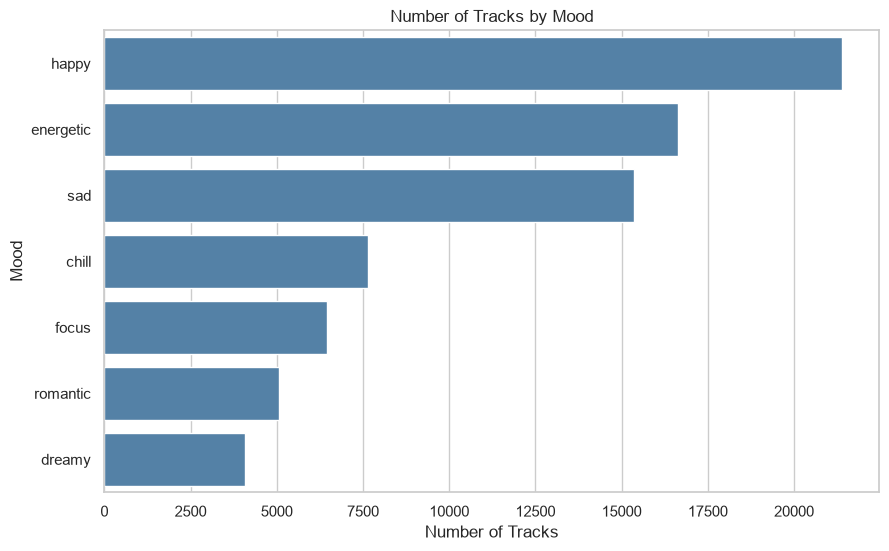

In [10]:
plt.figure(figsize=(10, 6))

sns.barplot(data=mood_counts, x="track_count", y="mood", color="steelblue")

plt.title("Number of Tracks by Mood")
plt.xlabel("Number of Tracks")
plt.ylabel("Mood")
plt.show()

#### 무드 비율 확인

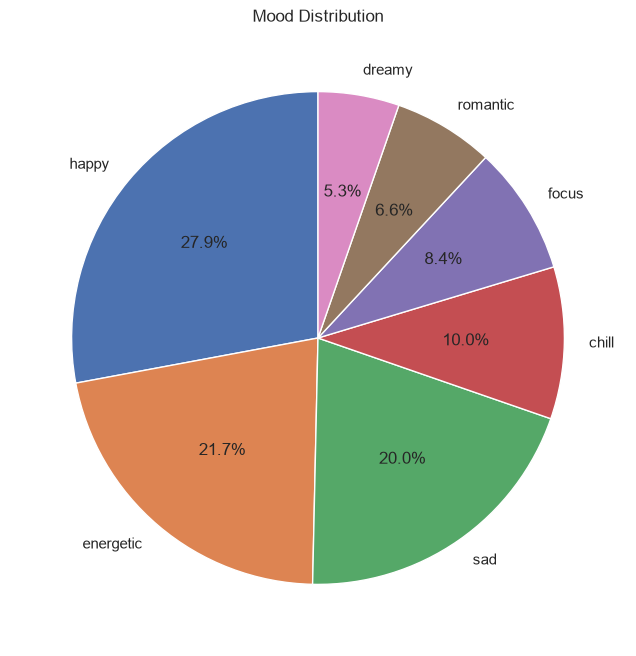

In [11]:
plt.figure(figsize=(8, 8))

plt.pie(mood_counts["track_count"], labels=mood_counts["mood"], autopct="%.1f%%", startangle=90)

plt.title("Mood Distribution")
plt.show()

#### 무드별 평균 Feature

In [12]:
mood_features = df.groupby("mood")[features].mean().round(3)

mood_features

,danceability,energy,tempo,acousticness,instrumentalness,valence
mood,,,,,,
chill,0.478,0.378,88.921,0.641,0.102,0.392
dreamy,0.427,0.306,141.432,0.826,0.316,0.385
energetic,0.555,0.880,140.938,0.068,0.150,0.391
focus,0.406,0.602,123.105,0.371,0.663,0.313
happy,0.673,0.750,124.978,0.211,0.061,0.766
romantic,0.627,0.507,104.734,0.639,0.028,0.685
sad,0.539,0.490,115.950,0.387,0.165,0.207


#### 무드별 Feature 히트맵

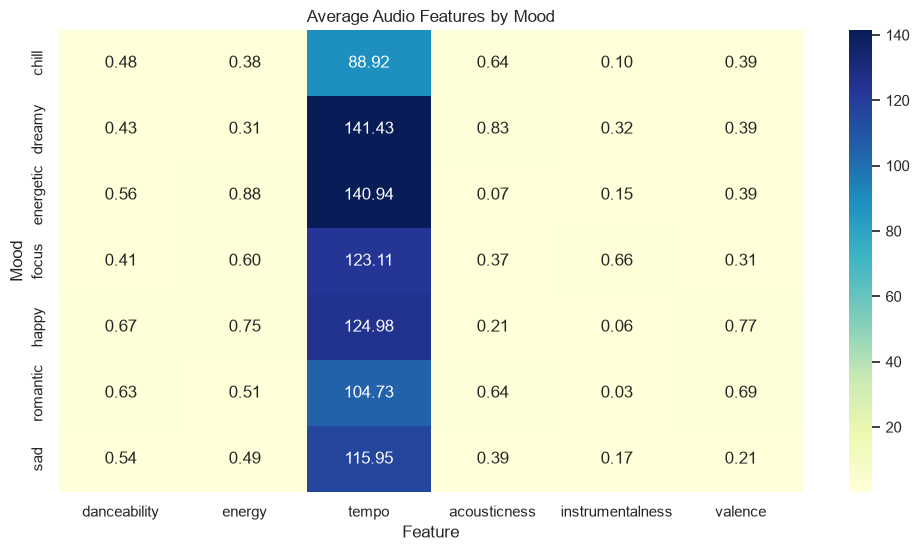

In [13]:
plt.figure(figsize=(12, 6))

sns.heatmap(mood_features, annot=True, fmt=".2f", cmap="YlGnBu")

plt.title("Average Audio Features by Mood")
plt.xlabel("Feature")
plt.ylabel("Mood")
plt.show()

#### 무드별 평균 Feature 그래프

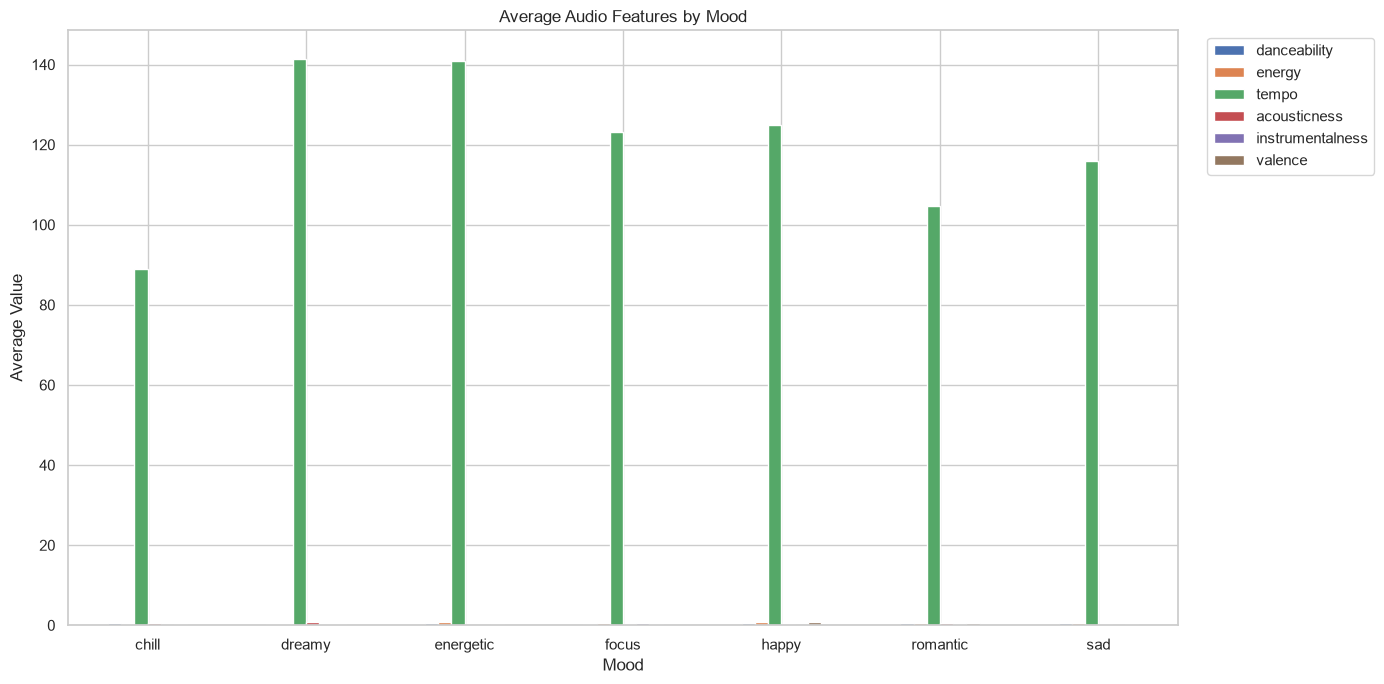

In [14]:
mood_features.plot(kind="bar", figsize=(14, 7))

plt.title("Average Audio Features by Mood")
plt.xlabel("Mood")
plt.ylabel("Average Value")
plt.xticks(rotation=0)
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

#### 무드별 Energy·Valence 분포

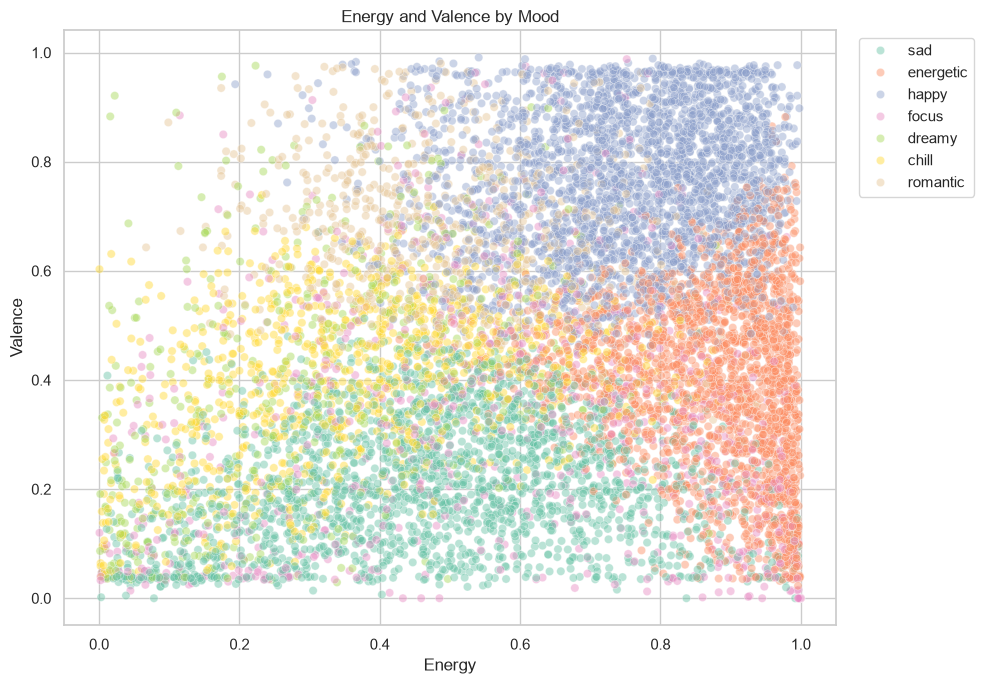

In [15]:
plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=df.sample(min(10000, len(df)), random_state=42),
    x="energy",
    y="valence",
    hue="mood",
    alpha=0.45,
    palette="Set2",
)

plt.title("Energy and Valence by Mood")
plt.xlabel("Energy")
plt.ylabel("Valence")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

#### 무드별 장르 확인

In [16]:
mood_genres = pd.crosstab(df["mood"], df["track_genre"])

mood_genres

track_genre,acoustic,afrobeat,alt-rock,alternative,ambient,anime,black-metal,bluegrass,blues,brazil,...,spanish,study,swedish,synth-pop,tango,techno,trance,trip-hop,turkish,world-music
mood,,,,,,,,,,,,,,,,,,,,,
chill,199,37,50,23,106,65,5,115,94,107,...,76,140,66,31,228,3,1,51,98,83
dreamy,82,23,10,2,221,26,0,149,35,22,...,25,18,29,8,252,1,0,25,54,22
energetic,55,80,207,71,13,270,355,13,73,101,...,165,18,88,128,0,142,313,91,144,116
focus,34,76,43,10,201,131,333,170,53,16,...,16,356,20,51,82,19,53,142,20,55
happy,143,563,299,65,4,230,18,279,247,250,...,361,90,266,320,31,58,25,261,228,40
romantic,83,55,28,7,5,17,0,137,62,61,...,49,53,45,22,297,0,0,25,57,16
sad,337,53,150,58,301,198,103,81,100,275,...,167,321,130,129,33,61,110,188,245,430


In [17]:
for mood in mood_counts["mood"]:
    print(f"\n[{mood}]")

    result = df[df["mood"] == mood]["track_genre"].value_counts().head(10)

    print(result)


[happy]
track_genre
forro        731
salsa        685
kids         577
afrobeat     563
dancehall    507
ska          503
disco        465
pagode       446
children     422
power-pop    404
Name: count, dtype: int64

[energetic]
track_genre
happy                711
hardstyle            680
drum-and-bass        618
heavy-metal          597
death-metal          503
metalcore            478
breakbeat            476
industrial           442
j-idol               439
progressive-house    393
Name: count, dtype: int64

[sad]
track_genre
mandopop       446
cantopop       437
world-music    430
chill          393
acoustic       337
study          321
gospel         317
french         306
ambient        301
dub            289
Name: count, dtype: int64

[chill]
track_genre
romance        376
opera          290
show-tunes     275
honky-tonk     266
disney         233
tango          228
acoustic       199
rock-n-roll    198
cantopop       173
comedy         168
Name: count, dtype: int64

[focus]
t

#### 무드별 대표 곡 확인

In [18]:
for mood in mood_counts["mood"]:
    print(f"\n[{mood}]")

    columns = [
        "track_name",
        "artists",
        "track_genre",
        "danceability",
        "energy",
        "tempo",
        "acousticness",
        "instrumentalness",
        "valence",
        "mood_score",
    ]

    display(df[df["mood"] == mood].sort_values("mood_score", ascending=False).head(10)[columns])


[happy]


,track_name,artists,track_genre,danceability,energy,tempo,acousticness,instrumentalness,valence,mood_score
19756,Ra Ta Ta 2011,Mallorca Cowboys,disco,0.812,0.999,138.007,0.1810,0.000000,0.948,0.947317
34848,Onze Kroeg,Lawineboys,happy,0.820,0.977,146.047,0.3140,0.000003,0.949,0.947111
47656,Purple People Eater - Party Dance Mix,Rik Gaynor,kids,0.881,0.928,156.003,0.1260,0.000034,0.965,0.944479
26879,American Pie,Os Barões Da Pisadinha,forro,0.786,0.935,172.128,0.6860,0.000143,0.974,0.944139
26511,O Piseiro Estourou,Márcia Fellipe;Os Barões Da Pisadinha;Vitor Fe...,forro,0.765,0.955,160.021,0.5550,0.000005,0.973,0.942499
55721,Arsch im Sand - Auf die Fresse DJ-Mix,Lollies,party,0.801,0.993,134.018,0.0932,0.000000,0.958,0.940429
16543,The Israelites,Apache Indian,dancehall,0.842,0.938,152.056,0.1520,0.000000,0.961,0.939977
68110,Police the Nation,The Planet Smashers,ska,0.753,0.958,167.944,0.0449,0.000000,0.964,0.939303
34607,Groeten Uit De Feesttent,Lawineboys,happy,0.744,0.970,155.031,0.1270,0.000000,0.963,0.936007
55725,Biergit (Wo es noch Bier gibt),Klaus & Klaus;Lorenz Büffel,party,0.852,0.978,130.072,0.1240,0.000000,0.942,0.934414



[energetic]


,track_name,artists,track_genre,danceability,energy,tempo,acousticness,instrumentalness,valence,mood_score
35285,Poing-Jump A Little Higher,Rotterdam Termination Source,happy,0.751,0.991,154.857,0.001010,0.1790,0.849,0.914278
8295,Tower Bass,Aphrodite,breakbeat,0.723,0.989,173.988,0.007630,0.5550,0.799,0.913523
35414,Rock That Body - Original Mix,Scott Brown,happy,0.724,0.987,169.993,0.001620,0.1790,0.841,0.912738
65993,Camionete Branca / Doutor do Agronegócio (feat...,Fernando & Sorocaba;Paulinho Mocelin,sertanejo,0.705,0.978,178.083,0.404000,0.0000,0.882,0.911656
34754,Allemaal Voor Jou,PartyfrieX,happy,0.778,0.997,150.034,0.053400,0.0000,0.756,0.911655
64355,La Esquina Del Movimiento,Alquimia La Sonora Del XXI,salsa,0.728,0.959,184.641,0.637000,0.0559,0.865,0.909985
21302,Bad News,A.M.C,drum-and-bass,0.772,0.994,173.956,0.000043,0.8060,0.590,0.904869
26689,Beijou Ta Novo,Washington Brasileiro,forro,0.758,0.949,174.009,0.378000,0.0000,0.848,0.904624
35040,Bass Slut - Alex BassJunkie & Riche Remix,S3RL;Alex Bassjunkie;Riche,happy,0.714,0.994,174.967,0.310000,0.0743,0.672,0.896315
43809,Broek Af - Anonymous Remix,De Antennes,j-dance,0.839,0.973,139.998,0.049800,0.8960,0.787,0.896169



[sad]


...

,track_name,artists,track_genre,danceability,energy,tempo,acousticness,instrumentalness,valence,mood_score
68881,Dromen,Bedtijd,sleep,0.1370,0.00779,141.805,0.994,0.995,0.0227,0.996054
68783,Soothing Baby Lullabies,Baby Sleep Music;Baby Lullaby;Monarch Baby Lul...,sleep,0.0934,0.00954,166.642,0.994,0.970,0.0427,0.995477
68781,Baby Sleep Music and Lullabies,Baby Sleep Music;Baby Lullaby;Monarch Baby Lul...,sleep,0.1640,0.00269,71.003,0.995,0.984,0.0514,0.995108
69035,Baby Songs,Baby Sleep Music;Baby Lullaby;Monarch Baby Lul...,sleep,0.1560,0.00387,77.038,0.994,0.982,0.0473,0.994787
76299,528Hz Energía curativa profunda,Mc_team,world-music,0.0865,0.00504,169.362,0.991,0.965,0.1380,0.993297
12995,"Wiegenlied, Op. 49, No. 4",Johannes Brahms;Mischa Maisky;Pavel Gililov,classical,0.0827,0.01340,81.694,0.992,0.961,0.0606,0.992739
53635,Like So Much Lost Time,Patrick O'Hearn,new-age,0.1060,0.01670,91.614,0.991,0.967,0.0354,0.992462
69033,Baby Music For Babies,Baby Sleep Music;Baby Lullaby;Monarch Baby Lul...,sleep,0.1950,0.00253,74.039,0.994,0.987,0.0391,0.992205
34256,Bellicoso,Little Symphony,guitar,0.1200,0.00330,164.398,0.985,0.988,0.0390,0.992074
3556,Brilliant Clouds,Max Richter,ambient,0.1720,0.01090,81.261,0.992,0.985,0.0305,0.991871



[romantic]


,track_name,artists,track_genre,danceability,energy,tempo,acousticness,instrumentalness,valence,mood_score
13276,"Canon in C, K.508A",Wolfgang Amadeus Mozart;Franz Schessl;Andreas ...,classical,0.375,0.226,71.455,0.986,0.652000,0.857,0.939751
13155,"The Nutcracker, Op. 71, Act II, Scene 3: No. 1...",Philadelphia Orchestra;Eugene Ormandy,classical,0.401,0.397,75.695,0.989,0.775000,0.903,0.911821
63242,Kanareechka,Tamara Tsereteli,romance,0.601,0.127,76.548,0.995,0.000363,0.818,0.905171
39984,I Ain't Gonna Love You Anymore,Hank Williams,honky-tonk,0.271,0.392,83.853,0.994,0.000000,0.763,0.898436
63235,Ekhali tsygane,Vadim Kozin,romance,0.483,0.268,82.027,0.995,0.005380,0.755,0.897814
20716,The Carnival of the Animals: Wild Jackasses (f...,David Ogden Stiers;Chie Nagatani;Nina Flyer,disney,0.562,0.134,79.520,0.951,0.005710,0.840,0.896570
73236,Garufa,Agustín Irusta,tango,0.428,0.434,62.874,0.963,0.119000,0.871,0.894730
63364,Бирюзовые колечки,Vadim Kozin,romance,0.572,0.244,88.716,0.993,0.014800,0.890,0.887489
12882,"Brandenburg Concerto No. 3 in G, BWV 1048: 1. ...",Johann Sebastian Bach;Berliner Philharmoniker;...,classical,0.513,0.296,84.367,0.990,0.803000,0.804,0.886690
39656,You Caused It All By Telling Lies,Hank Williams,honky-tonk,0.461,0.327,80.683,0.939,0.000000,0.810,0.883673



[dreamy]


,track_name,artists,track_genre,danceability,energy,tempo,acousticness,instrumentalness,valence,mood_score
69015,White Noise for Meditation,Meditation Music Zone,sleep,0.1220,0.01700,89.537,0.995,0.964,0.0602,0.994689
69029,Soft Piano,Baby Sleep Music;Baby Lullaby;Monarch Baby Lul...,sleep,0.1190,0.00448,151.665,0.995,0.953,0.0387,0.994283
68576,Anatomy of Change,Oto Roth,sleep,0.1310,0.00333,81.947,0.993,0.966,0.0349,0.993730
12892,"Piano Sonata No. 14 in C-Sharp Minor, Op. 27 N...",Ludwig van Beethoven;Murray Perahia,classical,0.1460,0.00241,166.462,0.995,0.945,0.0973,0.992043
3208,Dream 1 (before the wind blows it all away) - ...,Max Richter,ambient,0.2140,0.00144,72.046,0.995,0.968,0.0866,0.990404
3331,Wildlife Analysis,Boards of Canada,ambient,0.0936,0.02040,80.879,0.995,0.936,0.2910,0.990296
68751,Background Piano,Baby Sleep Music;Baby Lullaby;Monarch Baby Lul...,sleep,0.1880,0.00269,77.668,0.995,0.950,0.0347,0.989986
68913,Soft Baby Lullabies,Baby Sleep Music;Baby Lullaby;Monarch Baby Lul...,sleep,0.2330,0.00268,76.601,0.996,0.972,0.0705,0.989665
69038,At Rest,Mjuk,sleep,0.1880,0.00175,78.818,0.995,0.946,0.1910,0.989397
43200,Lima,Ali Phi,iranian,0.1440,0.00002,135.515,0.994,0.935,0.0000,0.989126


#### 무드 점수 분포

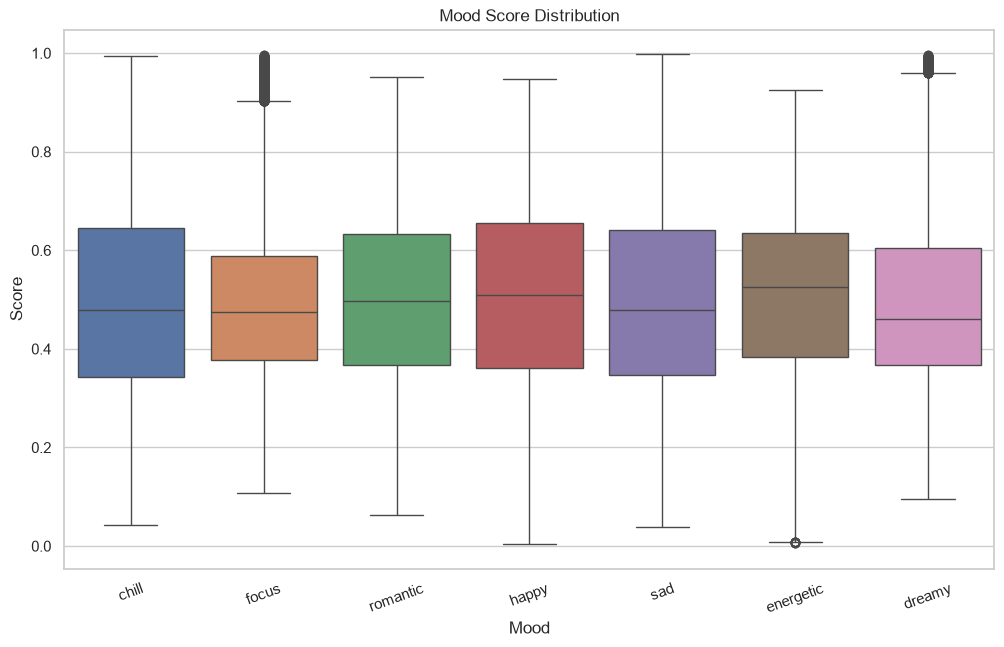

In [19]:
plt.figure(figsize=(12, 7))

sns.boxplot(data=mood_scores)

plt.title("Mood Score Distribution")
plt.xlabel("Mood")
plt.ylabel("Score")
plt.xticks(rotation=20)
plt.show()

#### 라벨 신뢰도 확인

In [20]:
sorted_scores = mood_scores.apply(
    lambda row: sorted(row, reverse=True), axis=1, result_type="expand"
)

sorted_scores.columns = [
    "highest_score",
    "second_score",
    "third_score",
    "fourth_score",
    "fifth_score",
    "sixth_score",
    "seventh_score",
]

df["mood_gap"] = sorted_scores["highest_score"] - sorted_scores["second_score"]

df["mood_gap"].describe()

count    7.663000e+04
mean     5.105149e-02
std      4.344295e-02
min      6.524860e-07
25%      1.634926e-02
50%      3.960769e-02
75%      7.546522e-02
max      3.023790e-01
Name: mood_gap, dtype: float64

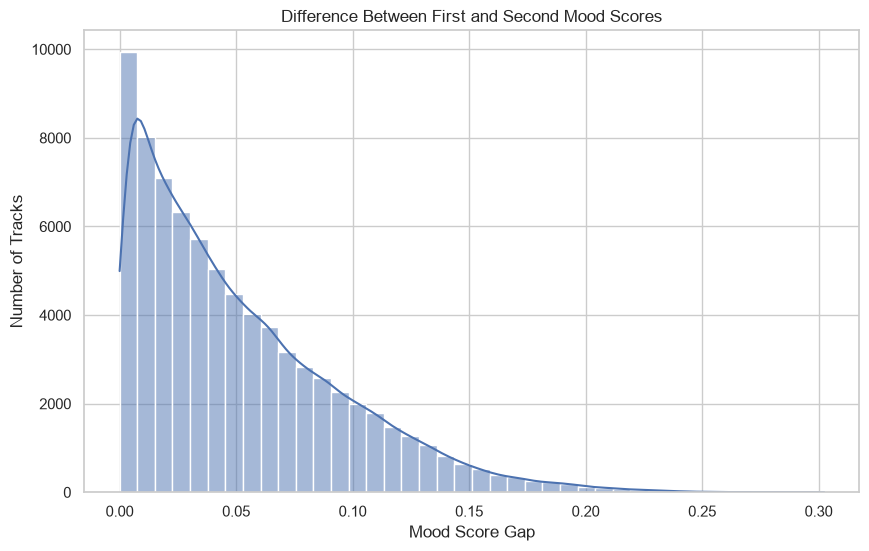

In [21]:
plt.figure(figsize=(10, 6))

sns.histplot(data=df, x="mood_gap", bins=40, kde=True)

plt.title("Difference Between First and Second Mood Scores")
plt.xlabel("Mood Score Gap")
plt.ylabel("Number of Tracks")
plt.show()

####  애매한 곡 확인

In [22]:
df[["track_name", "artists", "track_genre", "mood", "mood_score", "mood_gap"]].sort_values(
    "mood_gap"
).head(20)

,track_name,artists,track_genre,mood,mood_score,mood_gap
63543,I'm Only a Fool for You,Dybbukk,sad,sad,0.674285,6.524860e-07
56621,Raindrops,BigRicePiano,piano,dreamy,0.926720,6.524860e-07
24702,Frank Sinatra,Miss Kittin;The Hacker,electronic,happy,0.751961,1.304972e-06
66356,Baby It's Cold Outside,Idina Menzel;Michael Bublé,show-tunes,romantic,0.677917,1.304972e-06
56151,Hour of Rest,William Cas,piano,dreamy,0.961915,1.631215e-06
66530,Baby It's Cold Outside (duet with Michael Bublé),Idina Menzel;Michael Bublé,show-tunes,romantic,0.677913,2.283701e-06
67707,Marcha de la Bronca,Miguel Cantilo;Hilda Lizarazu;Pedro Y Pablo;Ri...,ska,energetic,0.581782,2.609944e-06
57758,Kurumugil,Vishal Chandrashekhar;Sai Vignesh,pop,chill,0.635538,2.609944e-06
51180,Ludens,Bring Me The Horizon,metalcore,energetic,0.479569,2.936187e-06
41719,Heat Waves,Glass Animals,indie-pop,romantic,0.649256,3.588673e-06


#### 저장

In [23]:
mood_features.to_csv("../reports/mood_feature_summary.csv", encoding="utf-8-sig")

mood_counts.to_csv("../reports/mood_counts.csv", index=False, encoding="utf-8-sig")

mood_scores.to_csv("../reports/mood_scores.csv", index=False, encoding="utf-8-sig")

In [24]:
output_columns = [
    "track_id",
    "track_name",
    "artists",
    "album_name",
    "track_genre",
    "duration_ms",
    "popularity",
    "danceability",
    "energy",
    "tempo",
    "acousticness",
    "instrumentalness",
    "valence",
    "mood",
    "mood_score",
    "mood_gap",
]

df_with_mood = df[output_columns].copy()

df_with_mood.to_csv("../data/processed/tracks_with_mood.csv", index=False, encoding="utf-8-sig")

print(df_with_mood.shape)
df_with_mood.head()

(76630, 16)


,track_id,track_name,artists,album_name,track_genre,duration_ms,popularity,danceability,energy,tempo,acousticness,instrumentalness,valence,mood,mood_score,mood_gap
0,5SuOikwiRyPMVoIQDJUgSV,Comedy,Gen Hoshino,Comedy,acoustic,230666,73,0.676,0.4610,87.917,0.0322,0.000001,0.715,romantic,0.594920,0.000680
1,4qPNDBW1i3p13qLCt0Ki3A,Ghost - Acoustic,Ben Woodward,Ghost (Acoustic),acoustic,149610,55,0.420,0.1660,77.489,0.9240,0.000006,0.267,chill,0.918206,0.070858
2,1iJBSr7s7jYXzM8EGcbK5b,To Begin Again,Ingrid Michaelson;ZAYN,To Begin Again,acoustic,210826,57,0.438,0.3590,76.332,0.2100,0.000000,0.120,sad,0.828143,0.054616
3,6lfxq3CG4xtTiEg7opyCyx,Can't Help Falling In Love,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,acoustic,201933,71,0.266,0.0596,181.740,0.9050,0.000071,0.143,dreamy,0.830717,0.001050
4,5vjLSffimiIP26QG5WcN2K,Hold On,Chord Overstreet,Hold On,acoustic,198853,82,0.618,0.4430,119.949,0.4690,0.000000,0.167,sad,0.766549,0.138466


## 무드 라벨링 결과

각 곡은 7개 무드 점수 중 가장 높은 무드로 분류

- Chill: 낮은 Energy·Tempo, 높은 Acousticness
- Focus: 높은 Instrumentalness·Acousticness, 낮은 Danceability
- Romantic: 높은 Acousticness, 낮은 Energy
- Happy: 높은 Valence·Energy·Danceability
- Sad: 낮은 Valence·Energy
- Energetic: 높은 Energy·Danceability·Tempo
- Dreamy: 높은 Acousticness·Instrumentalness, 낮은 Energy

사람이 직접 붙인 감정 라벨이 아니라 오디오 Feature로 만든 규칙 기반 라벨. 무드별 평균 Feature와 대표 곡을 보고 어색하면 가중치를 조정한다.

결과는 `data/processed/tracks_with_mood.csv`에 저장함